# 01 · Frame selection on a long video

A recognition model looks at a handful of frames. On a three-minute sports video the action is a small part of
the timeline, so *which* frames decides the answer, and decoding is what costs time. This notebook runs the
same model with evenly spaced frames and with `vam`'s keyframe sampler on one clip and shows what each did.

Needs: `pip install vam-runtime[hf] matplotlib`; a long clip (`CLIP` below; a THUMOS14 validation video by
default, any long file works). First run downloads VideoMAE (350 MB) and CLIP ViT-B/32 (600 MB).

In [1]:
import os
import time

import matplotlib.pyplot as plt
import numpy as np
import torch

import vam

CLIP = os.environ.get("VAM_CLIP", "data/thumos14/videos/video_validation_0000051.mp4")
device = "cuda" if torch.cuda.is_available() else "cpu"
video = vam.load_video(CLIP)
print(f"{CLIP}: {video.duration:.0f} s, {video.num_frames} frames at {video.fps:.0f} fps, {video.width}x{video.height}, {device}")

/home/vrishabh/Documents/Coding/vivaan/vam/data/thumos14/videos/video_validation_0000051.mp4: 170 s, 5091 frames at 30 fps, 320x180, cuda


## Uniform frames: the baseline
`UniformSampler(16)` reads 16 evenly spaced frames. Each read is a seek into the file.

In [2]:
model = vam.get_model("videomae-base-kinetics", device=device)
with vam.profile("uniform-16") as p:
    out_u = model(video, sampler=vam.UniformSampler(16))
print(p.report())
print(out_u.top_k(3))

/home/vrishabh/Documents/Coding/vivaan/vam/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Loading weights:   0%|          | 0/186 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 186/186 [00:00<00:00, 11936.05it/s]

stage         wall_ms   peak_mb
uniform-16      884.3     225.8
total           884.3
[('carving pumpkin', 0.14903977513313293), ('getting a tattoo', 0.048765625804662704), ('changing oil', 0.04829172044992447)]


## Keyframe sampler
`KeyframeSampler(8)` decodes only the file's keyframes (no inter-frame decoding), scores each with the packaged
class-free head on CLIP embeddings, picks the best, decodes a short window after each in parallel, and places
the frames at the peaks inside the windows. Half the frames of the baseline, and it carries its own timings.

In [3]:
sampler = vam.KeyframeSampler(8)  # scorer=None: the packaged head; CLIP runs on the GPU when there is one
with vam.profile("keyframe-8") as p:
    out_k = model(video, sampler=sampler)
print(p.report())
print(out_k.top_k(3))
kf = sampler.last_keyframes
print(f"{len(kf.times)} keyframes scanned, {len(sampler.last_windows)} windows chosen, fallback={sampler.last_fallback}")

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 398/398 [00:00<00:00, 97240.81it/s]

stage         wall_ms   peak_mb
keyframe-8     1087.4     660.0
total          1087.4
[('sword fighting', 0.12382008880376816), ('sharpening pencil', 0.060699712485075), ('carving pumpkin', 0.041636861860752106)]
24 keyframes scanned, 4 windows chosen, fallback=None


## What it looked at
Keyframe scores along the timeline, the windows it decoded, and where the two samplers' frames landed.

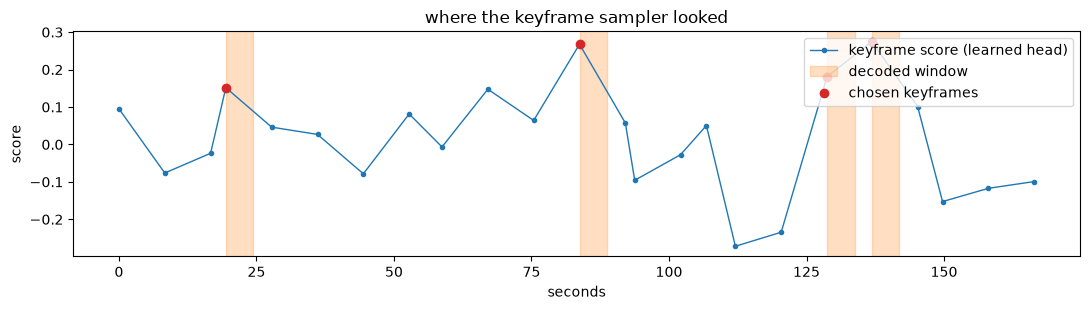

In [4]:
fig, ax = plt.subplots(figsize=(11, 3.2))
ax.plot(kf.times, sampler.last_scores, ".-", lw=1, label="keyframe score (learned head)")
for s, e in sampler.last_windows:
    ax.axvspan(s / video.fps, e / video.fps, color="tab:orange", alpha=0.25, label="decoded window")
ax.plot(kf.times[sampler.last_chosen], np.asarray(sampler.last_scores)[sampler.last_chosen], "o", color="tab:red",
        label="chosen keyframes")
ax.set_xlabel("seconds")
ax.set_ylabel("score")
handles, labels = ax.get_legend_handles_labels()
uniq = dict(zip(labels, handles))
ax.legend(uniq.values(), uniq.keys(), loc="upper right")
ax.set_title("where the keyframe sampler looked")
plt.tight_layout()
plt.show()

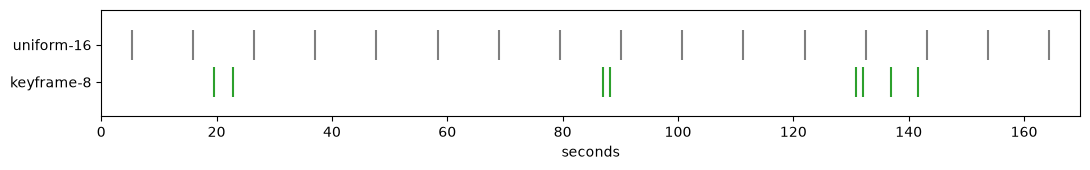

In [5]:
# frame positions chosen by each sampler
u_idx = np.array(vam.UniformSampler(16).select(video)) / video.fps
k_batch = sampler(video)
k_idx = k_batch.indices.numpy() / video.fps
fig, ax = plt.subplots(figsize=(11, 1.8))
ax.eventplot([u_idx, k_idx], lineoffsets=[1, 0], colors=["tab:gray", "tab:green"], linelengths=0.8)
ax.set_yticks([1, 0])
ax.set_yticklabels(["uniform-16", "keyframe-8"])
ax.set_xlabel("seconds")
ax.set_xlim(0, video.duration)
plt.tight_layout()
plt.show()

## Cost per stage, averaged
One call is noisy; repeat each a few times. On an RTX 5090 with THUMOS14 video the keyframe path costs about
150 ms whatever the budget, while uniform grows with the frame count because every frame is a seek
(`docs/results/thumos14_pdecode.md`).

In [6]:
def timed(sampler, n=3):
    ts = []
    for _ in range(n):
        t0 = time.perf_counter()
        model(video, sampler=sampler)
        if device == "cuda":
            torch.cuda.synchronize()
        ts.append((time.perf_counter() - t0) * 1000)
    return float(np.median(ts))


rows = [("uniform-4", timed(vam.UniformSampler(4))), ("uniform-16", timed(vam.UniformSampler(16))),
        ("keyframe-4", timed(vam.KeyframeSampler(4))), ("keyframe-16", timed(vam.KeyframeSampler(16)))]
for name, ms in rows:
    print(f"{name:12s} {ms:7.0f} ms")

uniform-4        121 ms
uniform-16       639 ms
keyframe-4       143 ms
keyframe-16      143 ms


On 200 THUMOS14 videos with a linear probe the keyframe sampler reaches 0.865 / 0.925 / 0.940 top-1 at
4 / 8 / 16 frames against uniform's 0.720 / 0.795 / 0.880, at the same or lower latency. The next notebook
lets you state that latency as a budget in milliseconds and have the runtime choose the rest.

In [7]:
video.close()
vam.runtime.shutdown_pools()  # stop the keyframe-scan workers (also happens at exit)